In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [5]:
!pip install --upgrade pip -q

!pip install transformers accelerate -q

import transformers, torch
print(f"✅ Transformers: {transformers.__version__}")
print(f"✅ PyTorch: {torch.__version__}")

print('CUDA:', torch.cuda.is_available())
print('GPU count:', torch.cuda.device_count())
print('GPU name:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A')

✅ Transformers: 5.20.2
✅ PyTorch: 2.11.0+cu130
CUDA: True
GPU count: 2
GPU name: Tesla T4


In [6]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "Qwen/Qwen2.5-3B-Instruct"

# Tokenizer and Model, with FP16 precision
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    dtype=torch.float16,
    device_map="auto"
)

print(f"✅ Model loaded in: {model.device}")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Model loaded in: cuda:0


In [7]:
import time
import numpy as np

def benchmark_single_request(prompt, max_new_tokens=128):
    """Measure TTFT & TPOT in a single request"""
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    
    # --- Measure TTFT (Time To First Token) ---
    start_time = time.perf_counter()
    
    with torch.no_grad():
        # Forward-pass - first token
        outputs = model(**inputs)
        # logits of next token
        next_token_logits = outputs.logits[:, -1, :]
        # first output token by greatest probability, use logit here
        first_token_id = torch.argmax(next_token_logits, dim=-1).unsqueeze(-1)
        
    first_token_time = time.perf_counter()
    ttft_ms = (first_token_time - start_time) * 1000  # s -> ms
    
    # --- Measure TPOT (Time Per Output Token) ---
    # Init inputs
    generated_ids = torch.cat([inputs.input_ids, first_token_id], dim=-1)
    
    # Record time elapsed on token generation
    decode_start_time = time.perf_counter()
    
    with torch.no_grad():
        for _ in range(max_new_tokens - 1):
            outputs = model(input_ids=generated_ids)
            next_token_logits = outputs.logits[:, -1, :]
            next_token_id = torch.argmax(next_token_logits, dim=-1).unsqueeze(-1)
            generated_ids = torch.cat([generated_ids, next_token_id], dim=-1)
            
    decode_end_time = time.perf_counter()
    
    # TPOT = time elapsed / #token
    total_decode_time = (decode_end_time - decode_start_time) * 1000  # s -> ms
    tpot_ms = total_decode_time / (max_new_tokens - 1) if max_new_tokens > 1 else 0
    
    return ttft_ms, tpot_ms

In [8]:
# Warm-up: cold-starting
print('Warming up...')
for _ in range(3):
    _ = benchmark_single_request("warm up the gpu", max_new_tokens=4)
print('Warm-up done.')

# Smoke test benchmark_single_request
ttft, tpot = benchmark_single_request("hello world", max_new_tokens=8)
print(f'TTFT: {ttft:.1f} ms, TPOT: {tpot:.1f} ms')

Warming up...
Warm-up done.
TTFT: 71.8 ms, TPOT: 75.1 ms


In [9]:
import random
import json

# Generate requests of different lengths
requests = []
input_lengths = [64, 128, 256, 512, 1024]

for length in input_lengths:
    for i in range(10):  # 10 requests for each input length
        # Random words are used here to formulate a request
        words = ['hello', 'world', 'data', 'latency', 'model', 'gpu', 'token', 'speed'] * (length // 8 + 1)
        random.shuffle(words)
        prompt = ' '.join(words[:length])
        
        requests.append({
            "prompt": prompt,
            "output_len": 128,   # Fix a 128 length output length
            "request_id": f"{length}-{i}"
        })

# Write to jsonl
with open('requests_10_per_length.jsonl', 'w') as f:
    for r in requests:
        f.write(json.dumps(r) + '\n')

print(f'Generated {len(requests)} requests and Saved in requests_10_per_length.jsonl')

Generated 50 requests and Saved in requests_10_per_length.jsonl


In [10]:
import json
import pandas as pd

with open('requests_10_per_length.jsonl', 'r') as f:
    requests = [json.loads(line) for line in f]

results = []
for req in requests:
    prompt = req['prompt']
    ttft, tpot = benchmark_single_request(prompt, max_new_tokens=64) 
    results.append({
        'request_id': req['request_id'],
        'input_length': req['request_id'].split('-')[0],
        'ttft_ms': ttft,
        'tpot_ms': tpot
    })
    print(f"Request {req['request_id']}: TTFT={ttft:.1f}ms, TPOT={tpot:.1f}ms")

# Save results
df_results = pd.DataFrame(results)
# df_results['input_length'] = df_results['input_length'].astype(int)
display(df_results.head())
df_results.to_csv('my_benchmark_results.csv', index=False)

Request 64-0: TTFT=102.2ms, TPOT=69.9ms
Request 64-1: TTFT=70.8ms, TPOT=72.8ms
Request 64-2: TTFT=77.3ms, TPOT=72.3ms
Request 64-3: TTFT=65.7ms, TPOT=66.9ms
Request 64-4: TTFT=67.3ms, TPOT=69.4ms
Request 64-5: TTFT=69.7ms, TPOT=70.1ms
Request 64-6: TTFT=67.0ms, TPOT=68.9ms
Request 64-7: TTFT=67.6ms, TPOT=68.2ms
Request 64-8: TTFT=70.2ms, TPOT=68.3ms
Request 64-9: TTFT=65.7ms, TPOT=67.0ms
Request 128-0: TTFT=70.5ms, TPOT=70.2ms
Request 128-1: TTFT=73.8ms, TPOT=72.2ms
Request 128-2: TTFT=68.2ms, TPOT=70.6ms
Request 128-3: TTFT=70.5ms, TPOT=72.2ms
Request 128-4: TTFT=72.3ms, TPOT=71.7ms
Request 128-5: TTFT=69.1ms, TPOT=72.7ms
Request 128-6: TTFT=66.5ms, TPOT=73.9ms
Request 128-7: TTFT=71.5ms, TPOT=75.0ms
Request 128-8: TTFT=68.0ms, TPOT=75.1ms
Request 128-9: TTFT=69.9ms, TPOT=74.7ms
Request 256-0: TTFT=69.5ms, TPOT=130.4ms
Request 256-1: TTFT=73.2ms, TPOT=127.1ms
Request 256-2: TTFT=67.4ms, TPOT=124.9ms
Request 256-3: TTFT=68.1ms, TPOT=123.2ms
Request 256-4: TTFT=68.7ms, TPOT=122.7ms
Requ

,request_id,input_length,ttft_ms,tpot_ms
0,64-0,64,102.177427,69.870031
1,64-1,64,70.762350,72.797906
2,64-2,64,77.331080,72.259348
3,64-3,64,65.736148,66.869861
4,64-4,64,67.260349,69.379962


In [11]:
import torch, transformers, platform, sys
env = f"""GPU: {torch.cuda.get_device_name(0)}
PyTorch: {torch.__version__}
Transformers: {transformers.__version__}
Python: {platform.python_version()}
Model: Qwen/Qwen2.5-3B-Instruct
Precision: float16
Output tokens: 64
Warm-up: 3 iterations before measurement
"""
print(env)
with open('/kaggle/working/env.txt', 'w') as f:
    f.write(env)

GPU: Tesla T4
PyTorch: 2.11.0+cu130
Transformers: 5.20.2
Python: 3.13.16
Model: Qwen/Qwen2.5-3B-Instruct
Precision: float16
Output tokens: 64
Warm-up: 3 iterations before measurement



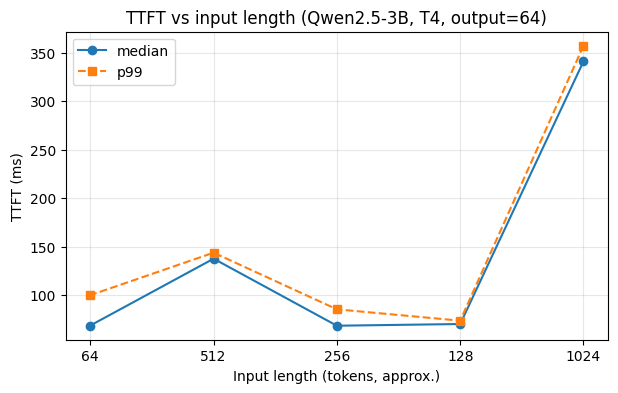

In [22]:
import matplotlib.pyplot as plt

g = df_results.groupby('input_length')['ttft_ms'].agg(['median', 'mean', 'count'])
g['p99'] = df_results.groupby('input_length')['ttft_ms'].quantile(0.99)

plt.figure(figsize=(7, 4))
plt.plot(g.index, g['median'], marker='o', label='median')
plt.plot(g.index, g['p99'], marker='s', linestyle='--', label='p99')
plt.xticks(sorted(df_results['input_length'].unique()))
plt.gca().invert_xaxis() 
plt.xlabel('Input length (tokens, approx.)')
plt.ylabel('TTFT (ms)')
plt.title('TTFT vs input length (Qwen2.5-3B, T4, output=64)')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/ttft_vs_input.png', dpi=150, bbox_inches='tight')
plt.show()

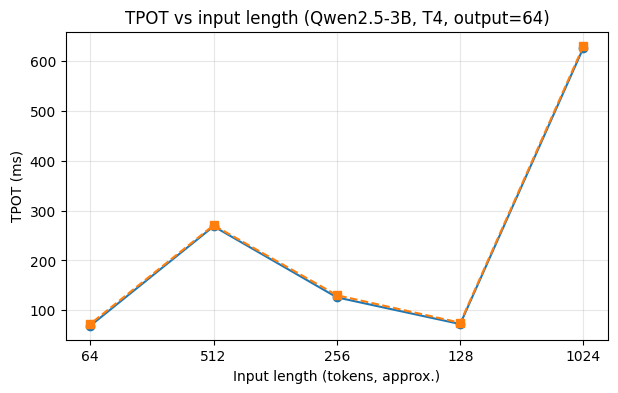

In [23]:
h = df_results.groupby('input_length')['tpot_ms'].agg(['median', 'mean', 'count'])
h["p99"] = df_results.groupby('input_length')['tpot_ms'].quantile(0.99)

plt.figure(figsize=(7, 4))
plt.plot(h.index, h['median'], marker='o', label='median')
plt.plot(h.index, h['p99'], marker='s', linestyle='--', label='p99')
plt.xticks(sorted(df_results['input_length'].unique()))
plt.gca().invert_xaxis() 
plt.xlabel('Input length (tokens, approx.)')
plt.ylabel('TPOT (ms)')
plt.title('TPOT vs input length (Qwen2.5-3B, T4, output=64)')
plt.grid(alpha=0.3)
plt.savefig('/kaggle/working/tpot_vs_input.png', dpi=150, bbox_inches='tight')
plt.show()

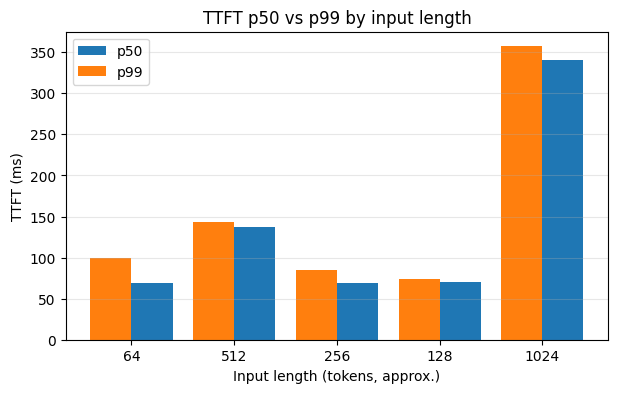

In [24]:
import numpy as np
x = np.arange(len(g.index))
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, g['median'], 0.4, label='p50')
plt.bar(x + 0.2, g['p99'], 0.4, label='p99')
plt.xticks(x, g.index)
plt.gca().invert_xaxis() 
plt.xlabel('Input length (tokens, approx.)')
plt.ylabel('TTFT (ms)')
plt.title('TTFT p50 vs p99 by input length')
plt.legend(); plt.grid(alpha=0.3, axis='y')
plt.savefig('/kaggle/working/ttft_p50_p99.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
summary = df_results.groupby('input_length').agg(
    ttft_p50=('ttft_ms', 'median'),
    ttft_p99=('ttft_ms', lambda s: s.quantile(0.99)),
    tpot_p50=('tpot_ms', 'median')
).round(1)
display(summary)